In [2]:
import pandas as pd

X_train = pd.read_csv("processed_data/X_train.csv")
X_test = pd.read_csv("processed_data/X_test.csv")

y_train = pd.read_csv("processed_data/y_train.csv").squeeze()
y_test = pd.read_csv("processed_data/y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (12294, 67)
X_test: (3057, 67)
y_train: (12294,)
y_test: (3057,)


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [4]:
y_pred = logistic_model.predict(X_test)

print("Predictions generated successfully.")
print("Total predictions:", len(y_pred))

Predictions generated successfully.
Total predictions: 3057


In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Phishing"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9538763493621197
Precision: 0.9536516853932584
Recall: 0.947662247034194
F1 Score: 0.9506475323766188

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.96      0.96      1624
    Phishing       0.95      0.95      0.95      1433

    accuracy                           0.95      3057
   macro avg       0.95      0.95      0.95      3057
weighted avg       0.95      0.95      0.95      3057


Confusion Matrix:
[[1558   66]
 [  75 1358]]


In [6]:
## Random forest
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [7]:
rf_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully.")
print("Total predictions:", len(rf_predictions))

Predictions generated successfully.
Total predictions: 3057


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1 Score:", f1_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["Legitimate", "Phishing"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Accuracy: 0.9751390251880929
Precision: 0.9754730203223546
Recall: 0.9713886950453594
F1 Score: 0.9734265734265735

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.98      1624
    Phishing       0.98      0.97      0.97      1433

    accuracy                           0.98      3057
   macro avg       0.98      0.97      0.98      3057
weighted avg       0.98      0.98      0.98      3057


Confusion Matrix:
[[1589   35]
 [  41 1392]]


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
7,url_length,0.098745
31,url_entropy,0.098066
48,no_of_internal_links,0.097822
46,no_of_hyperlinks,0.095459
6,domain_length,0.090148
35,count_www,0.064393
47,no_of_external_links,0.041803
45,no_of_Images,0.036790
40,average_length_of_words,0.035806
39,total_words_url,0.035028


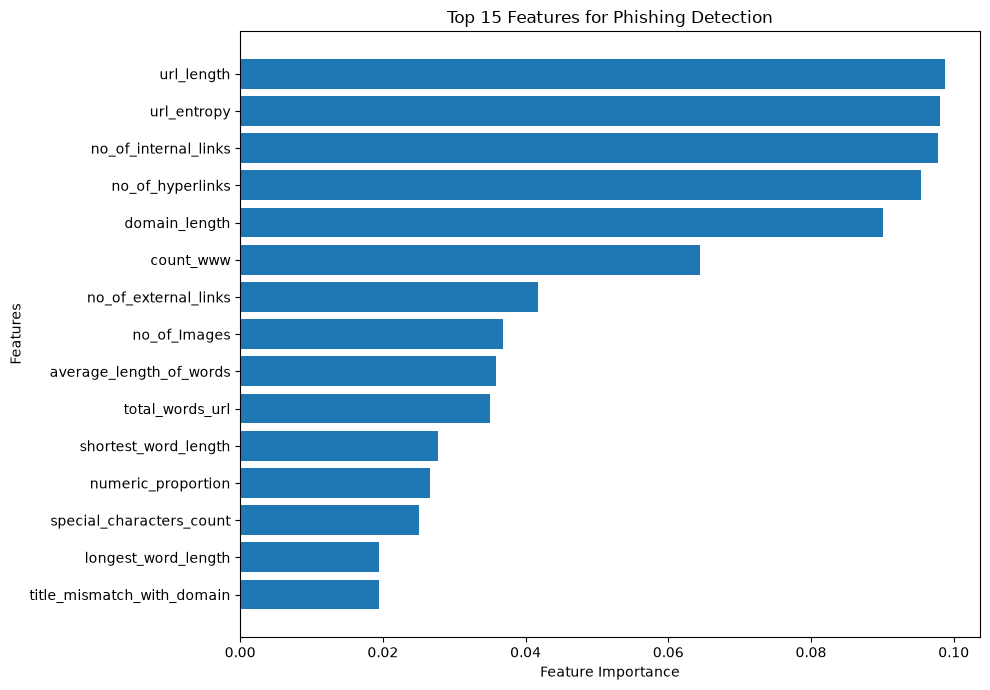

In [10]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Features for Phishing Detection")

plt.tight_layout()
plt.show()